In [1]:
import math
from scipy.integrate import odeint
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
import sys
from mpl_toolkits.mplot3d import Axes3D
from scipy.integrate import solve_ivp 
from numpy import linalg as LA
import importlib
import import_ipynb
import helper_function
import burgers_helper
from helper_function import *
from burgers_helper import *

In [2]:
# Reload all files containing helper functions
importlib.reload(helper_function)
importlib.reload(burgers_helper)

ModuleSpec(name='helper_function', loader=<import_ipynb.NotebookLoader object at 0x10b3fa7b0>, origin='helper_function.ipynb')

In [3]:
# Define time and spatial bound, grid points
# Spatial domain
N = 100
x = np.linspace(0, 2*np.pi, N, endpoint=False)
delta_x = x[1] - x[0]

# Time domain
T = 0.5
Nt = 10
t = np.linspace(0, T, 5)
delta_t = t[1] - t[0]

In [4]:
#Solve M = 0 system normally
M0 = 0
u_init_M0 = getinitcond(x, M0, ic_type='cond_1') 
u_init_flat_M0 = u_init_M0.flatten()
M0_result = odeint(GeneralBurgRHS, 
                   u_init_flat_M0, 
                   t, 
                   args = (delta_x,M0,N))

In [5]:
# Solve M = 1 system
M1 = 1
u_init_M1 = getinitcond(x, M1, ic_type='cond_1') 
u_init_flat_M1 = u_init_M1.flatten()

M1_result = odeint(
    GeneralBurgHierachy,
    u_init_flat_M1,
    t,
    args=(delta_x, M1, N)
)

In [6]:
# Initialize M=2 system
M2 = 2

u_init_M2 = getinitcond(x, M2, ic_type="cond_1")
u_init_flat_M2 = u_init_M2.flatten()

for i in range(len(t)-1):
    u0_from_M1 = M1_result[i, 0:N]      
    u1_from_M1 = M1_result[i, N:2*N]   
    
    u_from_M1 = (u0_from_M1, u1_from_M1)
    
    # Solve
    M2_result = odeint(GeneralBurgHierachy, u_init_flat_M2, t, 
                 args=(delta_x, M2, N, u_from_M1))
print(M2_result)

[[ 0.          0.          0.         ...  0.          0.
   0.        ]
 [ 0.         -0.02724571 -0.05373322 ...  0.03189786  0.02225919
   0.01135578]
 [ 0.         -0.02724571 -0.05373322 ...  0.0720159   0.05132827
   0.02644982]
 [ 0.         -0.02724571 -0.05373322 ...  0.12830815  0.09676565
   0.05140488]
 [ 0.         -0.02724571 -0.05373322 ...  0.20365959  0.17778883
   0.10490997]]


In [7]:
result_M2_normal = odeint(GeneralBurgRHS, u_init_flat_M2, t, args = (delta_x,M2,N))
print(result_M2_normal)

[[ 0.          0.          0.         ...  0.          0.
   0.        ]
 [ 0.         -0.00816531 -0.01617748 ...  0.0243596   0.01651387
   0.00831841]
 [ 0.         -0.01883018 -0.03702987 ...  0.05859035  0.04040676
   0.0205076 ]
 [ 0.         -0.03864011 -0.07310093 ...  0.12158431  0.09058664
   0.04779345]
 [ 0.         -0.10536927 -0.14484149 ...  0.21088892  0.21398295
   0.14442238]]


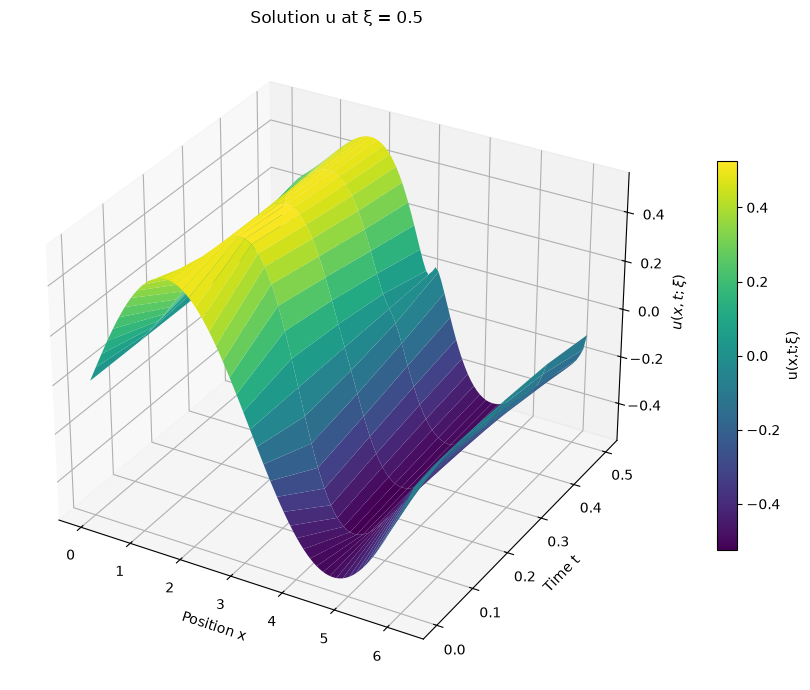

In [11]:
u0atallt_ = M2_result[:, 0:N]
u1atallt_ = M2_result[:, N:2*N]
u2atallt_ = M2_result[:, 2*N:3*N]
x_axis = x
y_axis = t

# Define variables
xi = 1/2
# Define Hermite polynomials
H0 = 1
H1 = xi
H2 = xi**2 - 1
Z = H0*u0atallt_ + H1*u1atallt_ + H2*u2atallt_
X,Y = np.meshgrid(x_axis, y_axis)

# Plot
fig = plt.figure(figsize=(12, 7))
ax = plt.axes(projection='3d')

surface = ax.plot_surface(
    X, Y, Z,
    cmap='viridis',
    edgecolor='none'
)

ax.set_xlabel('Position x')
ax.set_ylabel('Time t')
ax.set_zlabel(r'$u(x,t;\xi)$')
ax.set_title(f' Solution u at ξ = {xi}')

fig.colorbar(surface, ax=ax, shrink=0.6, label='u(x,t;ξ)')
plt.tight_layout()
plt.show()